# Great Salt Lake Surface Area from MODIS (2001–2025)

The Great Salt Lake in Utah has been shrinking for decades, as river water is diverted upstream and droughts hit the
basin. In this notebook I track the lake's surface area every 8 days since 2001 using MODIS surface reflectance
(`MODIS/061/MOD09A1`, 500 m) and the NDWI water index in Google Earth Engine:

**NDWI** = (green − NIR) / (green + NIR) = (band 4 − band 2) / (band 4 + band 2). Water has positive values.

What I added to my original script:

- **Clouds are removed** using the MODIS quality band, and **winter months are left out** (snow looks like water in NDWI).
- **The water threshold is chosen from the data** (Otsu's method on the NDWI histogram) instead of a fixed 0.1,
  turning my original histogram chart into an automatic choice.
- **Only nearly cloud-free images are used**, so a cloud over the lake is not mistaken for lost water.
- **Seasonal and long-term trends**, maps of where the lake has retreated, and a **check against the Landsat-based
  JRC water maps** (30 m).

## 1. Setup

Earth Engine results are saved to `outputs/gsl/` year by year, so **Restart & Run All** after a restart is quick.

In [1]:
import os, json
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

C:\Users\moham\anaconda3\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.18) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [2]:
import ee
ee.Authenticate(auth_mode="localhost")
ee.Initialize(project="#Your GEE username#")

## 2. Study area and settings

In [3]:
# Folders where I save tables and figures
FIG_DIR, OUT_DIR = "figures/gsl", "outputs/gsl"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# A box around the Great Salt Lake (replaces 'geometry' in my original script)
BBOX = [-113.15, 40.65, -111.85, 41.75]
roi = ee.Geometry.Rectangle(BBOX)
ROI_NAME = "Great Salt Lake, Utah"

START_YEAR, END_YEAR = 2001, 2025
THRESHOLD = None        # None = choose automatically (Otsu); or set a number such as 0.1 (my original value)
MIN_CLEAR = 0.90        # use an 8-day image only if at least 90% of the lake zone is cloud-free
WINTER_MONTHS = [12, 1, 2, 3]   # left out: snow on the exposed lakebed looks like water in NDWI
EARLY, LOW, RECENT = (2001, 2005), (2018, 2022), (2023, 2025)   # periods compared on the maps
SCALE = 500
FORCE_RECOMPUTE = False

## 3. MODIS NDWI with clouds and snow removed

I only measure inside the **lake zone**: everywhere the JRC Global Surface Water dataset has seen water at least once
since 1984. This keeps nearby land and Utah Lake out, while leaving room for the lake to grow or shrink.

In [4]:
def prepare(img):
    # Keep only clear pixels according to the MODIS quality band (StateQA): no cloud and no cloud shadow.
    # I do NOT use the MODIS snow/ice and internal-cloud flags here: they wrongly flag the bright salt crust and the
    # very salty lake water as snow or cloud, which would throw away almost every image of the Great Salt Lake.
    # Snow is handled instead by leaving out the winter months (WINTER_MONTHS in Section 2).
    qa = img.select("StateQA")
    clear = (qa.bitwiseAnd(3).eq(0)                  # bits 0-1: cloud state = clear
             .And(qa.bitwiseAnd(1 << 2).eq(0)))      # bit 2: cloud shadow
    bands = img.select(["sur_refl_b04", "sur_refl_b02"]).multiply(0.0001)
    ndwi = bands.normalizedDifference(["sur_refl_b04", "sur_refl_b02"]).rename("ndwi")
    return ndwi.updateMask(clear).copyProperties(img, ["system:time_start"])

modis = (ee.ImageCollection("MODIS/061/MOD09A1").filterDate(f"{START_YEAR}-01-01", f"{END_YEAR + 1}-01-01")
           .filter(ee.Filter.calendarRange(WINTER_MONTHS[-1] + 1, WINTER_MONTHS[0] - 1, "month")))   # skip winter
ndwi = modis.map(prepare)

lake_zone = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("max_extent").eq(1).selfMask().clip(roi)
px = ee.Image.pixelArea().divide(1e6)
zone_km2 = lake_zone.multiply(px).reduceRegion(ee.Reducer.sum(), roi, SCALE, maxPixels=1e10).getInfo()["max_extent"]
print(f"Lake zone (largest water extent seen since 1984): {zone_km2:,.0f} km²")

Lake zone (largest water extent seen since 1984): 6,322 km²


## 4. Choosing the water threshold

My original script plotted the NDWI histogram of the 2010 median image to choose a threshold. Here I use the same
histogram (inside the lake zone, which holds both open water and exposed lakebed) and let Otsu's method find the
value that best separates the two peaks (dry lakebed and water).

Otsu threshold: 0.289 | threshold used: 0.289


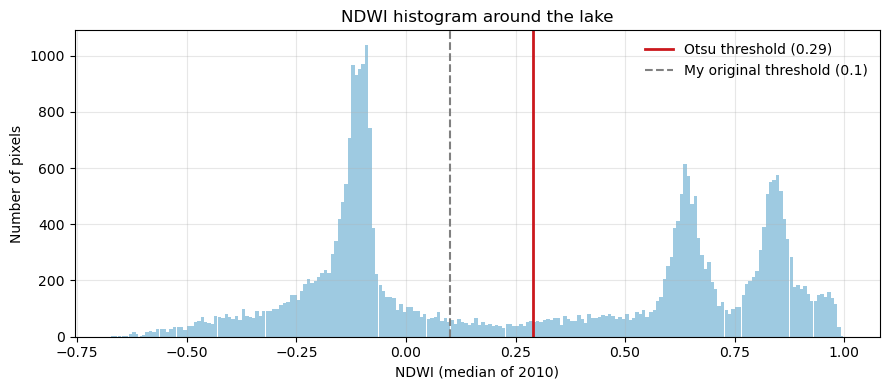

In [5]:
hist = (ndwi.filterDate("2010-01-01", "2011-01-01").median().updateMask(lake_zone)
          .reduceRegion(ee.Reducer.histogram(maxBuckets=200), roi, SCALE, maxPixels=1e10).getInfo()["ndwi"])
centers, counts = np.array(hist["bucketMeans"]), np.array(hist["histogram"], dtype=float)

def otsu(centers, counts):
    # Try every split point and keep the one with the largest separation between the two groups
    best_t, best_var = centers[0], -1
    total, total_mean = counts.sum(), (counts * centers).sum() / counts.sum()
    w0 = m0 = 0.0
    for i in range(len(counts) - 1):
        w0 += counts[i]; m0 += counts[i] * centers[i]
        w1 = total - w0
        if w0 == 0 or w1 == 0:
            continue
        mu0, mu1 = m0 / w0, (total_mean * total - m0) / w1
        var = w0 * w1 * (mu0 - mu1) ** 2
        if var > best_var:
            best_var, best_t = var, (centers[i] + centers[i + 1]) / 2
    return best_t

otsu_t = otsu(centers, counts)
THR = otsu_t if THRESHOLD is None else THRESHOLD
print(f"Otsu threshold: {otsu_t:.3f} | threshold used: {THR:.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(centers, counts, width=np.diff(centers).mean(), color="#9ecae1")
ax.axvline(otsu_t, color="#cb181d", lw=2, label=f"Otsu threshold ({otsu_t:.2f})")
ax.axvline(0.1, color="gray", ls="--", label="My original threshold (0.1)")
ax.set(xlabel="NDWI (median of 2010)", ylabel="Number of pixels", title="NDWI histogram around the lake")
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_ndwi_histogram.png"); plt.show()

## 5. Lake area every 8 days

For every 8-day image: the water area inside the lake zone, and how much of the zone was clear.
Each year is saved as soon as it is done.

In [6]:
AREA_CSV = f"{OUT_DIR}/gsl_area_8day.csv"
META_JSON = f"{OUT_DIR}/run_settings.json"

# If the threshold changed since the last run, the saved areas are no longer valid
settings = {"threshold": round(float(THR), 4), "min_clear": MIN_CLEAR, "qa": "cloud+shadow", "winter": WINTER_MONTHS}
if os.path.exists(META_JSON) and json.load(open(META_JSON)) != settings:
    print("Settings changed since last run - recomputing.")
    FORCE_RECOMPUTE = True
json.dump(settings, open(META_JSON, "w"))

def composite_stats(img):
    nd = img.select("ndwi")
    clear_km2 = nd.mask().gt(0).unmask(0).updateMask(lake_zone).multiply(px).rename("clear_km2")
    water_km2 = nd.gt(THR).updateMask(lake_zone).multiply(px).rename("water_km2")
    sums = ee.Image.cat(clear_km2, water_km2).reduceRegion(ee.Reducer.sum(), roi, SCALE, maxPixels=1e10)
    return ee.Feature(None, sums).set("date", img.date().format("YYYY-MM-dd"))

saved = pd.read_csv(AREA_CSV) if os.path.exists(AREA_CSV) and not FORCE_RECOMPUTE else pd.DataFrame()
done_years = set(pd.to_datetime(saved["date"]).dt.year) if len(saved) else set()
for year in range(START_YEAR, END_YEAR + 1):
    if year in done_years:
        continue
    fc = ndwi.filterDate(f"{year}-01-01", f"{year + 1}-01-01").map(composite_stats)
    rows = [f["properties"] for f in fc.getInfo()["features"]]
    saved = pd.concat([saved, pd.DataFrame(rows)], ignore_index=True)
    saved.to_csv(AREA_CSV, index=False)
    print(f"{year}: {len(rows)} images")

area = (saved.assign(date=lambda d: pd.to_datetime(d["date"])).drop_duplicates("date")
             .set_index("date").sort_index().astype(float))
area["clear_frac"] = area["clear_km2"] / zone_km2
good = area[area["clear_frac"] >= MIN_CLEAR]["water_km2"]
print(f"8-day images: {len(area)} | nearly cloud-free and used: {len(good)}")
print("Clear share of the lake zone (10th / 50th / 90th percentile):",
      np.round(area["clear_frac"].quantile([0.1, 0.5, 0.9]).values, 2))
if len(good) < 50:
    print("Very few usable images - lower MIN_CLEAR in Section 2 (see the clear-share numbers above).")
print("Usable images per month:", good.groupby(good.index.month).size().to_dict())

Settings changed since last run - recomputing.
2001: 29 images
2002: 30 images
2003: 30 images
2004: 30 images
2005: 30 images
2006: 30 images
2007: 30 images
2008: 30 images
2009: 30 images
2010: 30 images
2011: 30 images
2012: 30 images
2013: 30 images
2014: 30 images
2015: 30 images
2016: 30 images
2017: 30 images
2018: 30 images
2019: 30 images
2020: 30 images
2021: 30 images
2022: 30 images
2023: 30 images
2024: 30 images
2025: 30 images
8-day images: 749 | nearly cloud-free and used: 52
Clear share of the lake zone (10th / 50th / 90th percentile): [0.56 0.83 0.88]
Usable images per month: {4: 19, 5: 19, 6: 5, 7: 3, 8: 3, 9: 3}


## 6. Seasonal and long-term change

In [7]:
monthly = good.resample("MS").median()
annual = good.groupby(good.index.year).median()                                   # typical area each year
autumn = good[good.index.month.isin([9, 10, 11])].groupby(lambda d: d.year).mean()  # seasonal low (Sep–Nov)

# Plain float arrays (the year index from pandas is an integer type that SciPy's trend test can choke on)
years = annual.index.to_numpy(dtype=float)
values = annual.to_numpy(dtype=float)
print(f"Years with usable images: {len(years)} ({int(years.min())}–{int(years.max())})")
if len(years) < 5:
    raise RuntimeError("Too few years with nearly cloud-free images - lower MIN_CLEAR (e.g. 0.9) in Section 2.")
ts_slope, ts_int, ts_lo, ts_hi = stats.theilslopes(values, years)
tau, mk_p = stats.kendalltau(years, values)
early = annual.loc[EARLY[0]:EARLY[1]].mean()
low = annual.loc[LOW[0]:LOW[1]].mean()

summary = pd.Series({
    "Water threshold used (NDWI)": round(float(THR), 3),
    "Largest annual median area (km²), year": f"{annual.max():,.0f} ({annual.idxmax()})",
    "Smallest annual median area (km²), year": f"{annual.min():,.0f} ({annual.idxmin()})",
    "Smallest autumn area (km²), year": f"{autumn.min():,.0f} ({autumn.idxmin()})",
    f"Mean area {EARLY[0]}–{EARLY[1]} (km²)": round(early),
    f"Mean area {LOW[0]}–{LOW[1]} (km²)": round(low),
    "Change between these periods (%)": round(100 * (low / early - 1), 1),
    "Theil–Sen trend (km²/year)": round(ts_slope, 1),
    "Theil–Sen 95% range (km²/year)": f"[{ts_lo:.1f}, {ts_hi:.1f}]",
    "Mann–Kendall p-value": round(mk_p, 4),
}, name="value")
pd.DataFrame({"annual_median_km2": annual, "autumn_mean_km2": autumn}).round(1).to_csv(f"{OUT_DIR}/gsl_area_annual.csv")
monthly.round(1).to_csv(f"{OUT_DIR}/gsl_area_monthly.csv", header=["water_km2"])
summary.to_csv(f"{OUT_DIR}/gsl_summary.csv")
summary.to_frame()

Years with usable images: 21 (2001–2023)


,value
Water threshold used (NDWI),0.289
"Largest annual median area (km²), year","4,406 (2001)"
"Smallest annual median area (km²), year","2,071 (2020)"
"Smallest autumn area (km²), year","2,071 (2020)"
Mean area 2001–2005 (km²),3701
Mean area 2018–2022 (km²),2558
Change between these periods (%),-30.9
Theil–Sen trend (km²/year),-53.3
Theil–Sen 95% range (km²/year),"[-75.9, -31.5]"
Mann–Kendall p-value,0.0


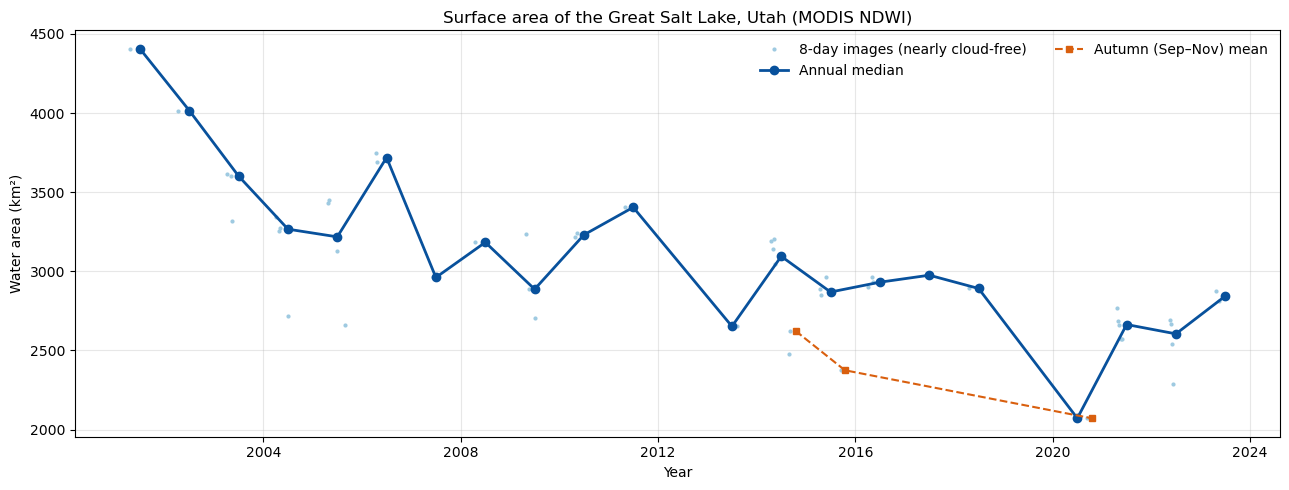

In [11]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(good.index, good.values, ".", color="#9ecae1", ms=4, label="8-day images (nearly cloud-free)")
ax.plot(pd.to_datetime(annual.index.astype(str) + "-07-01"), annual.values, "o-", color="#08519c", lw=2,
        label="Annual median")
ax.plot(pd.to_datetime(autumn.index.astype(str) + "-10-15"), autumn.values, "s--", color="#d95f0e", ms=4,
        label="Autumn (Sep–Nov) mean")
trend_x = pd.to_datetime(annual.index.astype(str) + "-07-01")  
ax.set(xlabel="Year", ylabel="Water area (km²)", title=f"Surface area of the {ROI_NAME} (MODIS NDWI)")
ax.legend(frameon=False, ncol=2); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/02_gsl_area_timeseries.png"); plt.show()

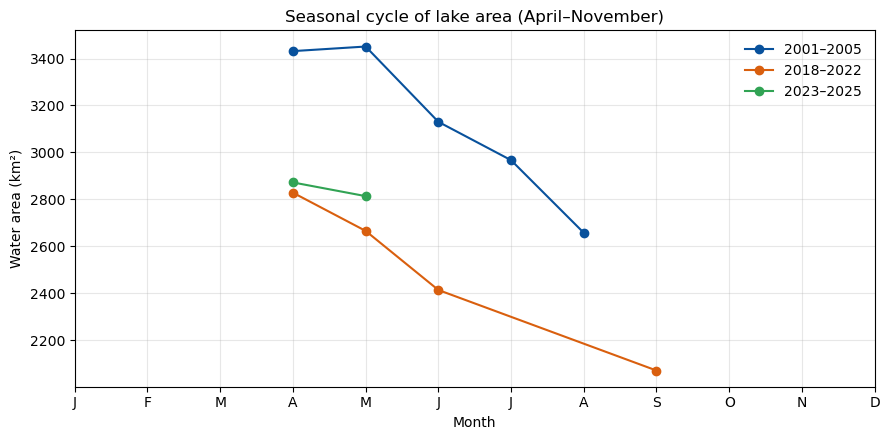

In [12]:
# Average seasonal cycle in three periods
fig, ax = plt.subplots(figsize=(9, 4.5))
for (y0, y1), color in zip([EARLY, LOW, RECENT], ["#08519c", "#d95f0e", "#31a354"]):
    sub = good.loc[f"{y0}-01-01":f"{y1}-12-31"]
    cycle = sub.groupby(sub.index.month).median()
    ax.plot(cycle.index, cycle.values, "o-", color=color, label=f"{y0}–{y1}")
ax.set(xticks=range(1, 13), xticklabels=list("JFMAMJJASOND"), xlabel="Month", ylabel="Water area (km²)",
       title="Seasonal cycle of lake area (April–November)")
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/03_gsl_seasonal_cycle.png"); plt.show()

## 7. Where the lake has retreated

For each period I count how often each pixel was water among its clear images (water frequency). Comparing the
early 2000s with the low years shows the exposed lakebed.

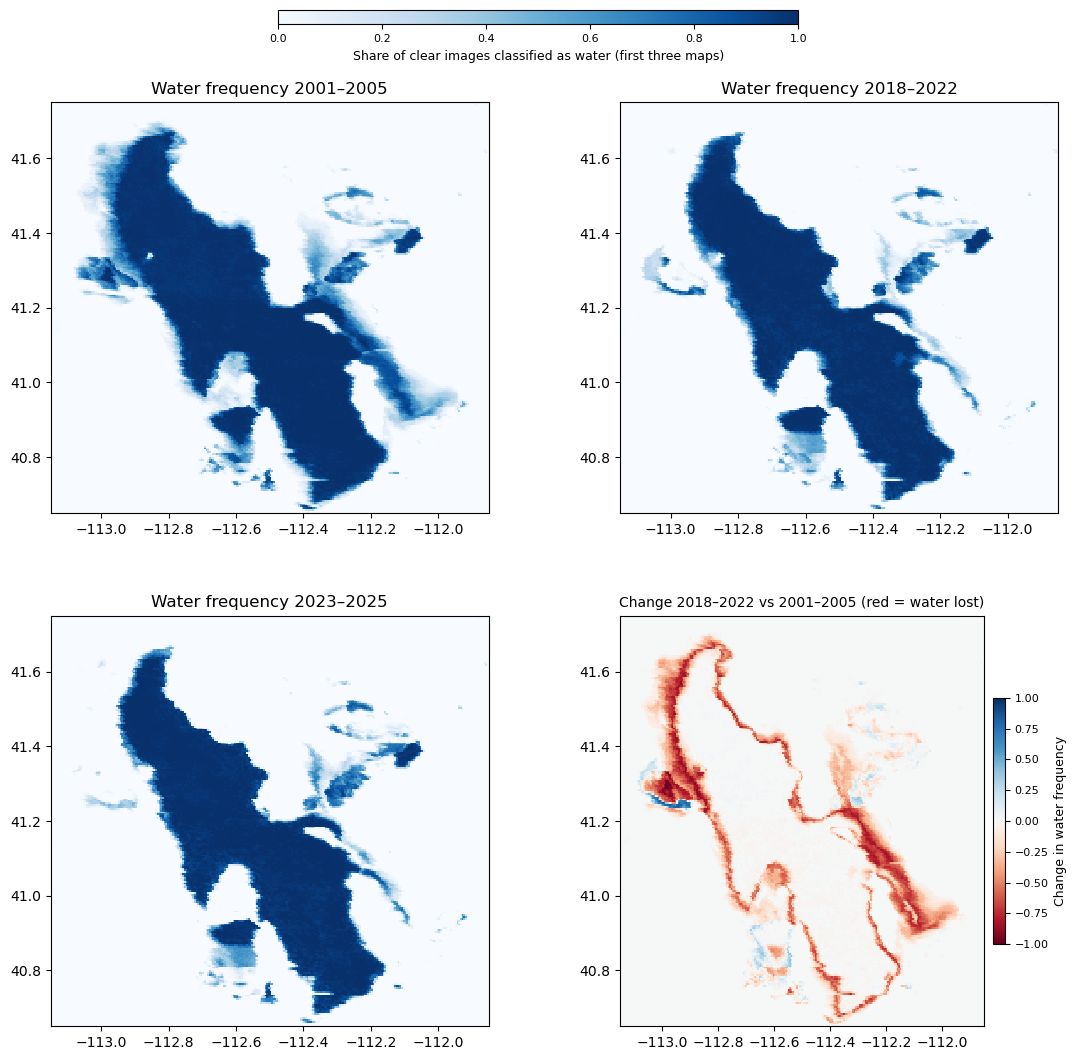

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 12))
fig.subplots_adjust(top=0.88, hspace=0.25, wspace=0.3)      # leave room at the top for the colour bar
for ax, p in zip(axes.flat[:3], (EARLY, LOW, RECENT)):
    pm = ax.pcolormesh(lon, lat, f[p], cmap="Blues", vmin=0, vmax=1, shading="nearest")
    ax.set_title(f"Water frequency {p[0]}–{p[1]}")

# One small, horizontal colour bar for the first three maps, placed above the figure so it covers nothing
cax = fig.add_axes([0.30, 0.945, 0.40, 0.012])              # [left, bottom, width, height] in figure fractions
cb = fig.colorbar(pm, cax=cax, orientation="horizontal")
cb.set_label("Share of clear images classified as water (first three maps)", fontsize=9)
cb.ax.tick_params(labelsize=8)

pm2 = axes.flat[3].pcolormesh(lon, lat, change, cmap="RdBu", vmin=-1, vmax=1, shading="nearest")
axes.flat[3].set_title(f"Change {LOW[0]}–{LOW[1]} vs {EARLY[0]}–{EARLY[1]} (red = water lost)", fontsize=10)
cb2 = fig.colorbar(pm2, ax=axes.flat[3], shrink=0.6, pad=0.02)
cb2.set_label("Change in water frequency", fontsize=9); cb2.ax.tick_params(labelsize=8)

## 8. Check against Landsat (JRC monthly water maps)

The JRC Global Surface Water monthly history maps water from Landsat at 30 m (available up to 2021). I compare my
monthly MODIS area with JRC for months where JRC saw at least 90% of the lake zone.

JRC 2001: done
JRC 2002: done
JRC 2003: done
JRC 2004: done
JRC 2005: done
JRC 2006: done
JRC 2007: done
JRC 2008: done
JRC 2009: done
JRC 2010: done
JRC 2011: done
JRC 2012: done
JRC 2013: done
JRC 2014: done
JRC 2015: done
JRC 2016: done
JRC 2017: done
JRC 2018: done
JRC 2019: done
JRC 2020: done
JRC 2021: done
Months compared: 25 | r = 0.915 | mean difference (MODIS − JRC) = -862 km²


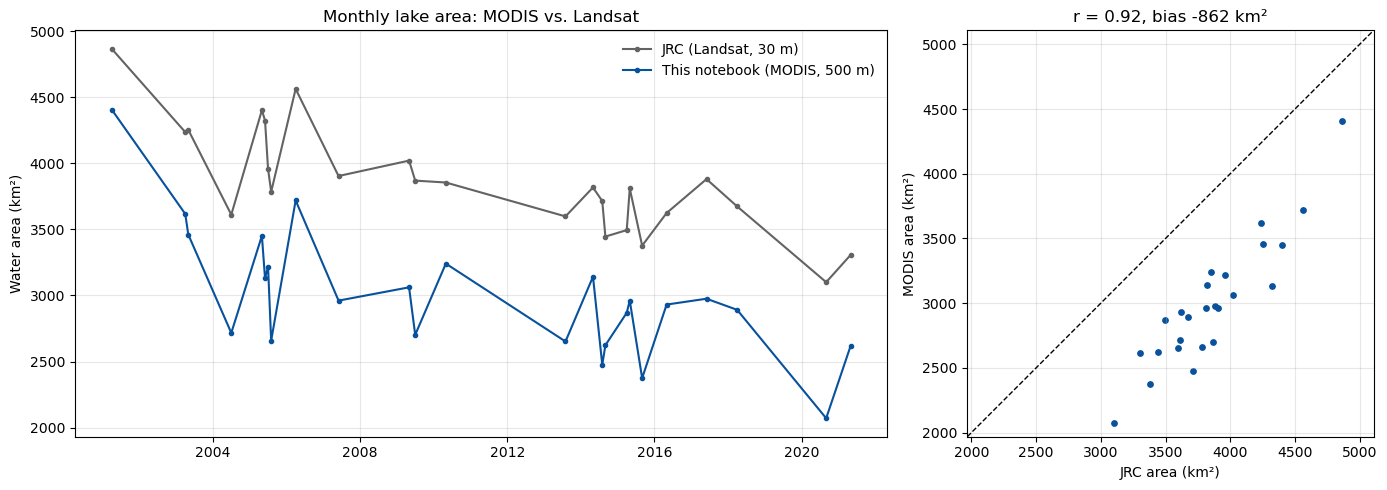

In [14]:
JRC_CSV = f"{OUT_DIR}/jrc_monthly_area.csv"
jrc_monthly = ee.ImageCollection("JRC/GSW1_4/MonthlyHistory")

def jrc_stats(img):
    w = img.select("water")
    sums = ee.Image.cat(w.eq(2).multiply(px).rename("jrc_water_km2"),
                        w.gt(0).multiply(px).rename("jrc_seen_km2")).updateMask(lake_zone).reduceRegion(
        ee.Reducer.sum(), roi, 90, maxPixels=1e11, tileScale=4)
    return ee.Feature(None, sums).set("date", img.date().format("YYYY-MM-01"))

jrc = pd.read_csv(JRC_CSV) if os.path.exists(JRC_CSV) and not FORCE_RECOMPUTE else pd.DataFrame()
jrc_years = set(pd.to_datetime(jrc["date"]).dt.year) if len(jrc) else set()
for year in range(START_YEAR, 2022):
    if year in jrc_years:
        continue
    fc = jrc_monthly.filterDate(f"{year}-01-01", f"{year + 1}-01-01").map(jrc_stats)
    jrc = pd.concat([jrc, pd.DataFrame([f["properties"] for f in fc.getInfo()["features"]])], ignore_index=True)
    jrc.to_csv(JRC_CSV, index=False)
    print(f"JRC {year}: done")

jrc_ok = (jrc.assign(date=lambda d: pd.to_datetime(d["date"])).set_index("date").astype(float)
             .query("jrc_seen_km2 >= 0.9 * @zone_km2")["jrc_water_km2"])
both = pd.concat([monthly.rename("modis_km2"), jrc_ok], axis=1, join="inner").dropna()
r, p_r = stats.pearsonr(both["modis_km2"], both["jrc_water_km2"])
bias = (both["modis_km2"] - both["jrc_water_km2"]).mean()
print(f"Months compared: {len(both)} | r = {r:.3f} | mean difference (MODIS − JRC) = {bias:+.0f} km²")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
ax1.plot(both.index, both["jrc_water_km2"], "o-", ms=3, color="#636363", label="JRC (Landsat, 30 m)")
ax1.plot(both.index, both["modis_km2"], "o-", ms=3, color="#08519c", label="This notebook (MODIS, 500 m)")
ax1.set(ylabel="Water area (km²)", title="Monthly lake area: MODIS vs. Landsat"); ax1.legend(frameon=False); ax1.grid(alpha=0.3)
lims = [both.min().min() * 0.95, both.max().max() * 1.05]
ax2.scatter(both["jrc_water_km2"], both["modis_km2"], s=15, color="#08519c")
ax2.plot(lims, lims, "k--", lw=1)
ax2.set(xlim=lims, ylim=lims, xlabel="JRC area (km²)", ylabel="MODIS area (km²)", title=f"r = {r:.2f}, bias {bias:+.0f} km²")
ax2.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/05_gsl_validation_jrc.png"); plt.show()

## 9. Notes

- **Data:** MODIS/Terra MOD09A1 v6.1 8-day surface reflectance (Vermote 2021); JRC Global Surface Water v1.4
  (Pekel et al. 2016).
- MODIS pixels are about 500 m, so the shoreline is blurred; the area is best used for trends and comparisons.
- The lake zone includes the evaporation ponds along the shore, which are managed separately from the lake and can
  add or remove water area independently of lake level.
- Shallow water over bright salt crust and the reddish, very salty north arm can have weak NDWI values; the Otsu
  threshold is chosen for the lake as a whole and may miss some very shallow margins.
- Winter months (December–March) are left out because snow on the exposed lakebed looks like water in NDWI.
  The MODIS snow/ice flags are not used, because they mislabel the bright salt crust and hypersaline water.
- Surface area is not the same as lake level or volume; the USGS lake-level gauges (e.g. Saltair Boat Harbor) are the
  standard reference for those.